Inclinação: 0.049  Intercepto: 0.030


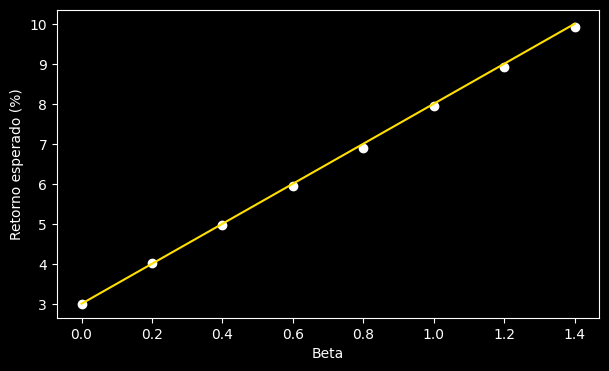

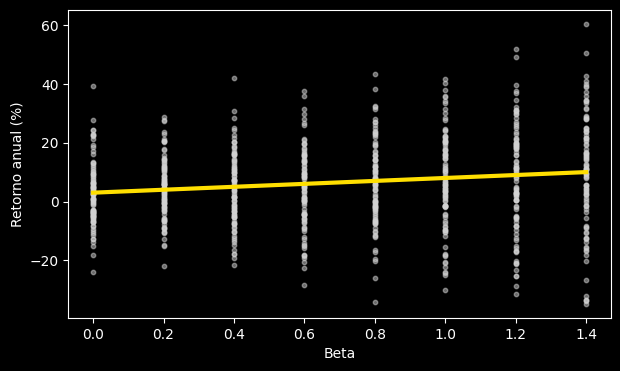

Risco próprio A: 5.9%
Risco próprio B: 19.7%
A: E(R) 9.3%, vol 21.1%
B: E(R) 5.3%, vol 21.0%


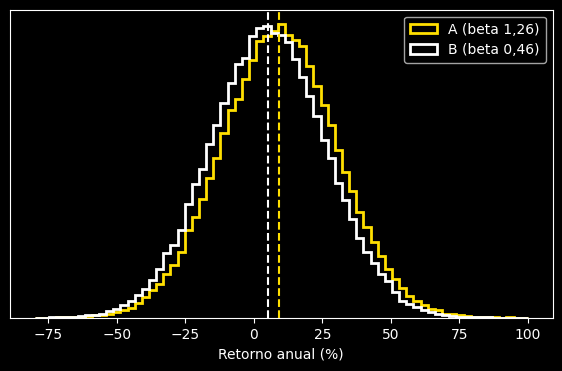


Beta   E(R) CAPM   Média simulada   Beta estimado
 0.0       3.0%            3.0%           0.000
 0.2       4.0%            4.0%           0.200
 0.4       5.0%            5.0%           0.400
 0.6       6.0%            5.9%           0.598
 0.8       7.0%            6.9%           0.799
 1.0       8.0%            7.9%           1.005
 1.2       9.0%            8.9%           1.199
 1.4      10.0%            9.9%           1.401


In [1]:
"""Quant Finance, Aula 2: modelo CAPM (Capital Asset Pricing Model).

    E(R) = Rf + beta * (Rm - Rf)

Mercado simulado: ativo livre de risco de 3% ao ano; o mercado paga 5% a mais
(8% ao ano) com variação de +-16%. Oito ações (betas de 0 a 1,4, de 0,2 em
0,2) seguem o mercado e têm também variação própria, com média zero: só o
beta gera retorno esperado. Duas ações destacadas (A e B) têm o mesmo risco
total (cerca de 21%) mas betas diferentes (1,26 e 0,46), logo retornos
esperados diferentes (9,3% e 5,3%).

Como rodar:  python aula2_capm.py     (gera 3 gráficos em graficos_capm/)
Requer: numpy e matplotlib. Material educacional; os dados são simulados.
"""
import os

os.makedirs("graficos_capm", exist_ok=True)

# Parâmetros do mercado
import numpy as np

rng = np.random.default_rng(42)
rf = 0.03
premio = 0.05
vol_mercado = 0.16
anos = 100000

# Mercado e ações simulados
betas = np.round(np.linspace(0, 1.4, 8), 1)
vol_propria = 0.10

media_m = rf + premio
r_mercado = rng.normal(media_m, vol_mercado, anos)
ruido = rng.normal(0, vol_propria, (anos, 8))
exc = r_mercado[:, None] - rf
r_acoes = rf + betas * exc + ruido

# Fórmulas: CAPM e beta
def capm(beta, rf, premio):
    return rf + beta * premio

def estimar_beta(r_acao, r_mercado):
    cov = np.cov(r_acao, r_mercado)[0, 1]
    return cov / np.var(r_mercado, ddof=1)

# Aplicar nas 8 ações
esperado = capm(betas, rf, premio)
retorno_medio = r_acoes.mean(axis=0)

beta_est = np.array([
    estimar_beta(r_acoes[:, i], r_mercado)
    for i in range(8)
])

a, b = np.polyfit(betas, retorno_medio, 1)
print(f"Inclinação: {a:.3f}  Intercepto: {b:.3f}")

# Gráfico 1: a linha do CAPM
import matplotlib.pyplot as plt
plt.style.use("dark_background")
amarelo = "#FFDF00"

plt.figure(figsize=(7, 4))
x = np.linspace(0, 1.4, 50)
plt.plot(x, capm(x, rf, premio) * 100,
         color=amarelo)
plt.scatter(betas, retorno_medio * 100,
            color="white")
plt.xlabel("Beta")
plt.ylabel("Retorno esperado (%)")
plt.savefig("graficos_capm/grafico1_linha_capm.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

# Gráfico 2: retornos anuais por beta
plt.figure(figsize=(7, 4))
n_pontos = 100
for i, beta in enumerate(betas):
    ys = r_acoes[:n_pontos, i] * 100
    xs = [beta] * n_pontos
    plt.scatter(xs, ys, s=10, alpha=0.5,
                color="lightgray")
plt.plot(x, capm(x, rf, premio) * 100,
         color=amarelo, linewidth=3)
plt.xlabel("Beta")
plt.ylabel("Retorno anual (%)")
plt.savefig("graficos_capm/grafico2_coluna_pontos.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

# Duas ações: risco próprio sob medida
def vol_propria_para(beta, vol_total=0.21):
    sistematica = beta * vol_mercado
    return (vol_total ** 2 - sistematica ** 2) ** 0.5

beta_a, beta_b = 1.26, 0.46
vol_a = vol_propria_para(beta_a)
vol_b = vol_propria_para(beta_b)
print(f"Risco próprio A: {vol_a:.1%}")
print(f"Risco próprio B: {vol_b:.1%}")

# Duas ações: simular e conferir
ruido_a = rng.normal(0, vol_a, anos)
ruido_b = rng.normal(0, vol_b, anos)
r_a = rf + beta_a * (r_mercado - rf) + ruido_a
r_b = rf + beta_b * (r_mercado - rf) + ruido_b

pares = [("A", r_a, beta_a), ("B", r_b, beta_b)]
for nome, r, bt in pares:
    esp = capm(bt, rf, premio)
    print(f"{nome}: E(R) {esp:.1%}, vol {r.std():.1%}")

# Gráfico 3: A contra B
plt.figure(figsize=(7, 4))
bins = np.linspace(-80, 100, 70)
plt.hist(r_a * 100, bins, histtype="step",
         color=amarelo, linewidth=2,
         label="A (beta 1,26)")
plt.hist(r_b * 100, bins, histtype="step",
         color="white", linewidth=2,
         label="B (beta 0,46)")
plt.axvline(r_a.mean() * 100, color=amarelo,
            linestyle="--")
plt.axvline(r_b.mean() * 100, color="white",
            linestyle="--")
plt.yticks([])
plt.xlabel("Retorno anual (%)")
plt.legend()
plt.savefig("graficos_capm/grafico3_duas_acoes.png", dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

# Resumo: retorno esperado (CAPM) x média simulada x beta estimado
print("\nBeta   E(R) CAPM   Média simulada   Beta estimado")
for b_, e_, m_, be_ in zip(betas, esperado, retorno_medio, beta_est):
    print(f"{b_:4.1f}   {e_:8.1%}   {m_:13.1%}   {abs(be_):13.3f}")